# Методы обработки и распознавания изображений¶

## Практическое занятие 8: Few/Zero Shot Learning

Мы привыкли, что задача машинного обучения предполагает наличие большого количества данных. А что если:

1. Существуют какие-то редкие случаи, примеров которых в обучающей выборке всего несколько штук. Тогда формально мы имеем задачу классификации на $C$ классов, из них $K < C$ классов имеют мало обучающих примеров, и нужно уметь различать между всеми классами, как многочисленными, так и малочисленными.

2. Для какой-то задачи в целом может быть сложно (долго, дорого, ненадежно...) собирать какие-то данные (например, компьютерная томография или МРТ). Здесь же у нас всего $K$ классов, и для каждого из этих классов имеется мало объектов в выборке.

Для таких задач был разработан ряд __Few Shot Learning__ алгоритмов. Если у нас $K$ редких классов, каждый из которых представлен $N$ объектами, то в англоязычной литературе такая Few Shot задача называется __$K$-way $N$-shot__ классификацией/регрессией/детекцией/...

Далее мы познакомимся с решениями, которые позволяют получать адекватное качество предсказаний, несмотря на крайне малое (или даже совсем отсутствующее!) количество данных.

## 0. Подгрузим данные для Few Shot классификации

In [1]:
import warnings

import pytorch_lightning as pl
import torch
import torchvision
from torch import nn
from torchmetrics.functional import accuracy
from torchvision import transforms

warnings.filterwarnings("ignore")
%matplotlib inline

Для начала соберем небольшую выборку. Пусть это будет подвыборка хорошо знакомой нам выборки CIFAR10, в которой 10 классов цветных изображений размера 32х32.

Сделаем класс `CifarSubset`, который будет представлять собой dataset, состоящий из подвыборки __N__ объектов каждого из 10 классов.
Вот поэтому так важно учить теорию вероятностей и мат.статистику.

In [2]:
class CifarSubset(torchvision.datasets.vision.VisionDataset):
    def __init__(self, root, k_n, train: bool, download: bool, transform):
        super().__init__(root, transform=transform, target_transform=None)

        self.k_n = k_n
        self.data = self.__sample_uniform_subset(root, train, download, transform)

    def __sample_uniform_subset(self, root, train, download, transform):
        """
        Метод вернет такую подвыборку выборки CIFAR10,
        что объектов каждого класса будет ровно k_n штук.

        :param: dataset — исходная выборка
        :param: k_n — количество объектов в каждом классе
        """

        self.cifar_full = torchvision.datasets.CIFAR10(
            root=root, train=train, download=download, transform=transform
        )

        number_of_classes = len(self.cifar_full.classes)
        class_count = [0 for _ in range(number_of_classes)]
        subset = []

        for image, label in self.cifar_full:
            # мы хотим ровно k_n объектов каждого класса
            if class_count[label] < self.k_n:
                subset.append((image, label))
                class_count[label] += 1

            # если каждый класс имеет k_n объектов - выходим из цикла
            if sum(class_count) == number_of_classes * self.k_n:
                break
        return subset

    def __getitem__(self, index):
        return self.data[index][0], self.data[index][1]

    def __len__(self):
        return len(self.data)

In [3]:
N_SHOT = 5  # количество объектов каждого класса в обучающей выборке

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)),
    ]
)

cifar_train_subset = CifarSubset(
    root="./cifar", k_n=N_SHOT, train=True, download=False, transform=transform
)

cifar_val_subset = CifarSubset(
    root="./cifar", k_n=N_SHOT, train=False, download=False, transform=transform
)

Многие алгоритмы для Few Shot (и особенно Meta) Learning лучше тренировать так называемыми __эпизодами__, где эпизодом называют ситуацию, максимально приближенную к условиям инференса. Например, если во время инференса мы будем просить модель классифицировать __N__ объектов каждого из __K__ классов, то и тренировать ее стоит батчами по __N__ * __K__ классов.

И так как в нашем случае __N__ * __K__ — это и есть _все_ наши данные, то у нас один эпизод эквивалентен одной эпохе.

In [4]:
# т.к. нам нужно обучаться эпизодами, батч должен содержать в себе сразу все данные
train_dataloader = torch.utils.data.DataLoader(
    cifar_train_subset,
    batch_size=N_SHOT * 10,  # 10 потому что в нашей выборке 10 классов
    shuffle=True,
    num_workers=0,
)
val_dataloader = torch.utils.data.DataLoader(
    cifar_val_subset, batch_size=N_SHOT * 10, shuffle=True, num_workers=0
)

Если воспользоваться решениями, которые были у нас до этого момента, то модель просто не выучит никаких закономерностей малочисленного класса и сильно переобучится.

Специально для таких задач был разработан ряд алгоритмов.

---

## 1. Few Shot Metric learning

Основная цель подходов данного вида - понять как выглядят выученные признаки (или эмбеддинги) типичного представителя каждого класса. Имея такие "прототипы" классов можно будет сравнивать признаки каждого из объектов с признаками каждого прототипа и выбирать тот, который наиболее похож на наш объект. Для того чтобы это работало, нужно убедиться, что во время обучения мы делаем так, что похожие объекты находятся рядом в пространстве признаков, а непохожие — далеко друг от друга (совсем как в задаче кластеризации).

---

Верхнеуровнево это всегда выглядит примерно одинаково:

1. На тех данных, что у нас имеются, обучается какая-то модель, выходом которой будут __не вероятности классов__, а __многомерный вектор признаков__ (можно взять любую из наших предыдущих моделей классификации/регрессии и отбросить последний классификационный слой).

2. Функция потерь подбирается таким образом, чтобы модель училась группировать между собой похожие данные.

3. В случае __K__-way __N__-shot классификации как во время обучения, так и во время инференса, происходит одно и то же. Какой-то процент из __N__ объектов каждого класса выбирается для формирования прототипа класса путем усреднения их признаков. Такая подвыборка будет называться вспомогательным множеством или __support set__. А оставшиеся объекты (которые мы, собственно, будем сравнивать с этим прототипом) называются множеством запросов или __query set__.

---

1. Построим простую свёрточную архитектуру, выходом которой для каждого объекта будет многомерный вектор выученных признаков:

In [5]:
class PrototypeNet(nn.Module):
    def __init__(self, input_dim=3, hid_dim=64, output_dim=64):
        super(PrototypeNet, self).__init__()

        self.encoder = nn.Sequential(
            self.__conv_block(input_dim, hid_dim),
            self.__conv_block(hid_dim, hid_dim),
            self.__conv_block(hid_dim, hid_dim),
            self.__conv_block(hid_dim, output_dim),
        )

    def __conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        x = self.encoder(x)
        return x.view(x.size(0), -1)

2. Теперь нужно выбрать такой функционал потерь, который будет штрафовать за:

  - большие расстояния между объектом и прототипом его класса
  - маленькие расстояния между объектом и прототипом _не_ его класса

  Так как готовых решений в торче нет, придется писать свой Loss... Чтобы не подбирать математику, описывающую нужные нам условия, воспользуемся подходом, представленным в [данной работе](https://arxiv.org/pdf/1703.05175.pdf). Тогда формирование функционала ошибки будет выглядеть следующим образом:

---

- Для каждого класса $c$:
    - Для каждого объекта $q$ из нашего __query_set($с$)__
      
  $$
  Loss +=  {1 \over N_c * N_q} * \left[\text{dist}(\text{emb}(q), p_c) + \log{\sum_{classes} e^{-\text{dist}(\text{emb}(q), p_{class})}} \right],
  $$

  где $\text{emb}(q)$ — эмбеддинг, полученный после того как объект $q$ прошел через нашу свёрточную сеть, а $\text{dist}(\text{emb}(q), p_c)$ — какая-то функция расстояния между этим эмбеддингом и прототипом $p_c$ класса $c$.
---
  С первого взгляда происходит что-то страшное, и непонятно почему взяты именно такие значения. Но если приглядеться, то будет понятно, что первое слагаемое в скобках - это просто расстояние от нашего объекта до прототипа своего класса, а второе слагаемое (в виде суммы) становится тем меньше, чем дальше наш объект от всех остальных прототипов.
  
  Таким образом, минимизируя представленный функционал по параметрам нейросети, мы как раз приближаем наш объект к своему прототипу и отдаляем от всех остальных!

In [6]:
class PrototypeLoss(nn.Module):
    def __init__(self, n_shot: int):
        super(PrototypeLoss, self).__init__()
        self.n_shot = n_shot
        self.__prototypes: list = None

    def __distance(self, inp, other):
        return torch.linalg.norm(inp - other)

    def __prototype_loss(
        self,
        predicted_embeddings: torch.Tensor,
        target_labels: torch.Tensor,
        support_percent: float = 0.6,
    ):
        """
        :param predicted_embeddings: векторы признаков, полученные в результате работы модели; shape = (N, emb_size)
        :param target_labels: список целевых классов; shape=(N)
        :param: support_percent: процент данных каждого класса, который будет использоваться для формирования прототипа класса
        """

        assert 0 < support_percent < 1

        classes = torch.unique(target_labels)
        n_classes = len(classes)  # количество классов за эпизод

        # количество данных для определения прототипа класса
        n_support = int(self.n_shot * support_percent)
        # количество данных для сравнения с прототипом класса
        n_query = self.n_shot - n_support

        prototypes = []  # прототипы класса (количество классов, вектор признаков)
        class_queries = []

        for c in classes:
            supports = predicted_embeddings[target_labels == c][:n_support]
            queries = predicted_embeddings[target_labels == c][n_support:]

            # прототип класса - это усредненное значение всех support объектов
            prototypes.append(supports.mean(0))
            # запросы класса - это все объекты, не попавшие в support
            class_queries.append(queries)

        loss = torch.tensor(0.0)

        for i, queries in enumerate(class_queries):
            for query in queries:  # пробегаемся по всем объектам класса i
                loss += self.__distance(prototypes[i], query)

                distances = torch.stack(
                    [
                        self.__distance(query, p)
                        for ci, p in enumerate(prototypes)
                        if i != ci
                    ]
                )
                # добавим значение, обратное сумме этих расстояний
                # чем больше расстояния, тем меньше мы наказываем модель

                loss += torch.log(torch.sum(torch.exp(-distances)))

        # сохраним прототипы для возможности дальнейших предсказаний
        self.prototypes = torch.stack(prototypes)

        return loss / (n_classes * n_query)

    def forward(self, predicted_embeddings, targets) -> torch.Tensor:
        return self.__prototype_loss(predicted_embeddings, targets)

    def get_class_prototypes(self) -> list:
        return self.__prototypes

Теперь осталось знакомым нам образом собрать все это дело в один LightningModule

In [7]:
class FewShotMetricLearner(pl.LightningModule):
    def __init__(self, n_shot: int) -> None:
        super().__init__()

        self.model = PrototypeNet()
        self.loss = PrototypeLoss(n_shot)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=1e-2)
        # это значение заполнится позже, во время расчета ошибки
        self.prototypes = None

    def forward(self, x) -> torch.Tensor:
        return self.model(x)

    def configure_optimizers(self):
        return self.optimizer

    def predict_labels(self, batch_embeddings):
        if self.prototypes == None:
            raise ValueError("self.prototypes was not set")

        ans = []
        for e in batch_embeddings:
            dists = torch.linalg.norm(self.prototypes - e, dim=1)
            ans.append(torch.argmin(dists))

        return torch.stack(ans)

    def training_step(self, train_batch, batch_idx) -> torch.Tensor:
        images, target = train_batch
        embeddings = self.forward(images)

        loss = self.loss(embeddings, target)
        # label_predictions = self.predict_labels(embeddings)

        self.log("train_loss", loss, prog_bar=True)
        return loss

    def validation_step(self, val_batch, batch_idx) -> None:
        images, target = val_batch
        embeddings = self.forward(images)

        loss = self.loss(embeddings, target)
        self.prototypes = self.loss.prototypes

        label_predictions = self.predict_labels(embeddings)
        acc = accuracy(
            label_predictions,
            target,
            task="multiclass",
            num_classes=10
        )

        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)

In [8]:
few_shot_metric_learner = FewShotMetricLearner(n_shot=N_SHOT)

trainer = pl.Trainer(accelerator="cpu", max_epochs=100)
trainer.fit(few_shot_metric_learner, train_dataloader, val_dataloader)

GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ PrototypeNet  │  113 K │ train │     0 │
│ 1 │ loss  │ PrototypeLoss │      0 │ train │     0 │
└───┴───────┴───────────────┴────────┴───────┴───────┘

Trainable params: 113 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 113 K                                                                                                
Total estimated model params size (MB): 0.452                                                                      
Modules in train mode: 23                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=100` reached.


In [9]:
metrics = trainer.callback_metrics
print("Final metrics:", metrics)

if "val_acc" in metrics:
    print("Final val_acc:", metrics["val_acc"].item())

Final metrics: {'train_loss': tensor(-69.2392), 'val_loss': tensor(5.0888), 'val_acc': tensor(0.6200)}
Final val_acc: 0.6200000047683716


In [10]:
results = trainer.validate(few_shot_metric_learner, val_dataloader)
print(results)  # здесь будет средний val_acc по всем валидационным батчам

Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.6000000238418579     │
│         val_loss          │     3.871783494949341     │
└───────────────────────────┴───────────────────────────┘

[{'val_loss': 3.871783494949341, 'val_acc': 0.6000000238418579}]


Мы классифицируем объекты с accuracy ~0.6, обучив (__примерно за минуту на cpu__) простейшую свёрточную сеть всего на __5 объектах (!!!)__ каждого класса.

Теперь все переделаем, пусть будет 2 минуты, но метрики должны стать лучше!

Можно перезапустить ядро.

In [11]:
import warnings
warnings.filterwarnings("ignore")

import pytorch_lightning as pl
import torch
import torch.nn.functional as F
import torchvision

from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchmetrics.functional import accuracy
from torchvision import transforms

In [12]:
class CifarFewShotSubset(Dataset):
    def __init__(self, root, n_shot, train, download, transform=None):
        self.transform = transform
        self.n_shot = n_shot

        base_dataset = torchvision.datasets.CIFAR10(
            root=root,
            train=train,
            download=download,
            transform=None,
        )

        class_counts = {i: 0 for i in range(10)}
        selected = []

        for image, label in base_dataset:
            if class_counts[label] < n_shot:
                selected.append((image, label))
                class_counts[label] += 1

            if all(class_counts[c] == n_shot for c in class_counts):
                break

        self.data = selected

        print(f"[DEBUG] Dataset created: train={train}, total={len(self.data)}")
        print(f"[DEBUG] Per-class counts: {class_counts}")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image, label = self.data[idx]

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [13]:
# Трансформации и DataLoader. Для train добавлены лёгкие аугментации

N_SHOT = 5

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.247, 0.243, 0.261)),
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.247, 0.243, 0.261)),
])

cifar_train_subset = CifarFewShotSubset(
    root="cifar",
    n_shot=N_SHOT,
    train=True,
    download=False,
    transform=train_transform,
)

cifar_val_subset = CifarFewShotSubset(
    root="cifar",
    n_shot=N_SHOT,
    train=False,
    download=False,
    transform=val_transform,
)

train_dataloader = DataLoader(
    cifar_train_subset,
    batch_size=N_SHOT * 10,
    shuffle=False,
    num_workers=0,
)

val_dataloader = DataLoader(
    cifar_val_subset,
    batch_size=N_SHOT * 10,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(train_dataloader))
images, labels = batch
print("[DEBUG] First train batch:", images.shape, labels.shape, torch.unique(labels))

[DEBUG] Dataset created: train=True, total=50
[DEBUG] Per-class counts: {0: 5, 1: 5, 2: 5, 3: 5, 4: 5, 5: 5, 6: 5, 7: 5, 8: 5, 9: 5}
[DEBUG] Dataset created: train=False, total=50
[DEBUG] Per-class counts: {0: 5, 1: 5, 2: 5, 3: 5, 4: 5, 5: 5, 6: 5, 7: 5, 8: 5, 9: 5}
[DEBUG] First train batch: torch.Size([50, 3, 32, 32]) torch.Size([50]) tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


Сеть и loss. Здесь сделаем нормальный prototypical loss через torch.cdist и cross_entropy, потому что это ближе к стандартной формулировке prototypical networks и намного логичнее, чем предыдущий вложенный цикл.

In [14]:
class PrototypeNet(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=128, output_dim=128):
        super().__init__()

        self.encoder = nn.Sequential(
            self.conv_block(input_dim, hidden_dim),
            self.conv_block(hidden_dim, hidden_dim),
            self.conv_block(hidden_dim, hidden_dim),
            self.conv_block(hidden_dim, output_dim),
        )

    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.1),
        )

    def forward(self, x):
        x = self.encoder(x)
        return x.view(x.size(0), -1)

In [15]:
class PrototypeLoss(nn.Module):
    def __init__(self, n_shot, support_count=3):
        super().__init__()
        self.n_shot = n_shot
        self.support_count = support_count
        self.prototypes = None
        self.classes = None

    def forward(self, embeddings, targets):
        classes = torch.unique(targets)
        prototypes = []
        query_embeddings = []
        query_targets = []

        for class_idx, c in enumerate(classes):
            class_embeddings = embeddings[targets == c]

            if class_embeddings.shape[0] != self.n_shot:
                raise ValueError(
                    f"Expected {self.n_shot} samples for class {int(c)}, "
                    f"got {class_embeddings.shape[0]}"
                )

            supports = class_embeddings[:self.support_count]
            queries = class_embeddings[self.support_count:]

            prototype = supports.mean(dim=0)
            prototypes.append(prototype)

            for q in queries:
                query_embeddings.append(q)
                query_targets.append(class_idx)

        prototypes = torch.stack(prototypes)
        query_embeddings = torch.stack(query_embeddings)
        query_targets = torch.tensor(query_targets, device=embeddings.device)

        distances = torch.cdist(query_embeddings, prototypes)
        logits = -distances
        loss = F.cross_entropy(logits, query_targets)

        self.prototypes = prototypes.detach()
        self.classes = classes.detach()

        return loss

Новый FewShotMetricLearner. Здесь всё согласовано: loss задаёт прототипы, предсказание идёт через те же прототипы, accuracy считается по актуальному API TorchMetrics с task="multiclass".

In [16]:
class FewShotMetricLearner(pl.LightningModule):
    def __init__(self, n_shot, lr=1e-3, weight_decay=1e-4):
        super().__init__()

        self.model = PrototypeNet()
        self.loss_fn = PrototypeLoss(n_shot=n_shot, support_count=3)

        self.lr = lr
        self.weight_decay = weight_decay

        self.prototypes = None
        self.prototype_classes = None

    def forward(self, x):
        return self.model(x)

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.lr,
            weight_decay=self.weight_decay,
        )

    def predict_labels(self, embeddings):
        if self.prototypes is None or self.prototype_classes is None:
            raise ValueError("Prototypes are not initialized.")

        distances = torch.cdist(embeddings, self.prototypes)
        pred_indices = torch.argmin(distances, dim=1)
        pred_labels = self.prototype_classes[pred_indices]
        return pred_labels

    def training_step(self, batch, batch_idx):
        images, target = batch
        embeddings = self(images)

        loss = self.loss_fn(embeddings, target)
        self.prototypes = self.loss_fn.prototypes
        self.prototype_classes = self.loss_fn.classes

        self.log("train_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
        return loss

    def validation_step(self, batch, batch_idx):
        images, target = batch
        embeddings = self(images)

        loss = self.loss_fn(embeddings, target)
        self.prototypes = self.loss_fn.prototypes
        self.prototype_classes = self.loss_fn.classes

        label_predictions = self.predict_labels(embeddings)

        acc = accuracy(
            label_predictions,
            target,
            task="multiclass",
            num_classes=10
        )

        self.log("val_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
        self.log("val_acc", acc, prog_bar=True, on_step=False, on_epoch=True)

        return {"val_loss": loss, "val_acc": acc}

Проверка одного батча до обучения. Это даёт гарантию, что всё вообще согласовано по формам и типам.

In [17]:
few_shot_metric_learner = FewShotMetricLearner(n_shot=N_SHOT)

batch = next(iter(train_dataloader))
images, target = batch

with torch.no_grad():
    embeddings = few_shot_metric_learner(images)
    print("[DEBUG] embeddings shape:", embeddings.shape)

loss = few_shot_metric_learner.loss_fn(embeddings, target)
print("[DEBUG] manual loss:", loss.item())

# ВАЖНО: переносим прототипы из лосса в модель
few_shot_metric_learner.prototypes = few_shot_metric_learner.loss_fn.prototypes
few_shot_metric_learner.prototype_classes = few_shot_metric_learner.loss_fn.classes

preds = few_shot_metric_learner.predict_labels(embeddings)
print("[DEBUG] preds shape:", preds.shape)
print("[DEBUG] preds unique:", torch.unique(preds))

[DEBUG] embeddings shape: torch.Size([50, 512])
[DEBUG] manual loss: 2.4184775352478027
[DEBUG] preds shape: torch.Size([50])
[DEBUG] preds unique: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


loss_fn посчитал loss и сохранил prototypes и classes внутри себя,

Мы явно присвоили их в few_shot_metric_learner.prototypes и few_shot_metric_learner.prototype_classes,

predict_labels больше не падает, потому что прототипы инициализированы.

Обучение и итоговая оценка.

In [18]:
few_shot_metric_learner = FewShotMetricLearner(n_shot=N_SHOT)

trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=50,
    num_sanity_val_steps=0,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
)

trainer.fit(few_shot_metric_learner, train_dataloader, val_dataloader)

print("Final metrics:", trainer.callback_metrics)

if "val_acc" in trainer.callback_metrics:
    print("Final val_acc:", trainer.callback_metrics["val_acc"].item())

val_results = trainer.validate(few_shot_metric_learner, dataloaders=val_dataloader, verbose=False)
print("Validate results:", val_results)

GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ PrototypeNet  │  447 K │ train │     0 │
│ 1 │ loss_fn │ PrototypeLoss │      0 │ train │     0 │
└───┴─────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 447 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 447 K                                                                                                
Total estimated model params size (MB): 1.789                                                                      
Modules in train mode: 27                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=50` reached.


Output()

Final metrics: {'val_loss': tensor(4.2558), 'val_acc': tensor(0.5400), 'train_loss': tensor(0.1450)}
Final val_acc: 0.5400000214576721


Validate results: [{'val_loss': 4.255831718444824, 'val_acc': 0.5400000214576721}]


In [19]:
print("Final metrics:", trainer.callback_metrics)

if "val_acc" in trainer.callback_metrics:
    print("Final val_acc:", trainer.callback_metrics["val_acc"].item())

val_results = trainer.validate(few_shot_metric_learner, dataloaders=val_dataloader, verbose=False)
print("Validate results:", val_results)

Output()

Final metrics: {'val_loss': tensor(4.2558), 'val_acc': tensor(0.5400)}
Final val_acc: 0.5400000214576721


Validate results: [{'val_loss': 4.255831718444824, 'val_acc': 0.5400000214576721}]


2 минуты есть, а вот метрика не выросла. )))

CifarSubset делает подвыборку: по N_SHOT картинок на каждый из 10 классов CIFAR‑10.

При N_SHOT = 5 датасет — это всего 50 картинок на train и 50 на val.

DataLoader берёт batch_size = N_SHOT * 10, то есть весь датасет на каждом шаге (50 примеров: по 5 на класс).

Лосс строит один эпизод: из этих 5 картинок на класс он берёт часть как support, часть как query, считает прототипы и ошибку по одному эпизоду.

То есть train:
* не видит «ещё эпизоды» — один и тот же маленький эпизод гоняется много эпох подряд;
* не видит «ещё примеры» — N_SHOT действительно задаёт и размер датасета, и размер эпизода.

В такой "игрушечной" конфигурации:
* модель очень быстро выучивает прототипы по этим 10 классам,
* затем валидация измеряет по тем же классам и похожим примерам, и метрика упирается в потолок архитектуры / лосса, а не в количество примеров.

Методические выводы:
* аугментации — они в принципе полезны, когда у тебя много эпох и больше данных; на 50 картинках и прототипическом лоссе по одному эпизоду их эффект может быть почти не виден.
* увеличение сети — тоже в целом разумный шаг, но без изменения постановки (больше данных, больше эпизодов) это просто делает модель чуть сложнее, а потолок метрики остаётся примерно там же.

## Задание.

1. Отладить минимальный рабочий baseline:
* стабильное чтение CIFAR‑subset;
* корректный лосс и метрика;
* одна‑две эпохи обучения;
* читабельное val_acc.

2. Показать влияние few‑shot параметров:
* сравнить N_SHOT = 1, 5, 10 при фиксированной архитектуре;
* возможно, разное supportpercent (сколько из N_SHOT идёт в support vs query).

3. Только после этого добавить:
* аугментации как способ «увеличивать» количество примеров;
* усиление encoder’а.

In [54]:
import matplotlib.pyplot as plt
import numpy as np

In [21]:
N_SHOT = 5

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            (0.4914, 0.4822, 0.4465),
            (0.247, 0.243, 0.261)
        ),
    ]
)

cifar_train_subset = CifarSubset(
    root="./cifar",
    k_n=N_SHOT,
    train=True,
    download=False,
    transform=transform
)

cifar_val_subset = CifarSubset(
    root="./cifar",
    k_n=N_SHOT,
    train=False,
    download=False,
    transform=transform
)

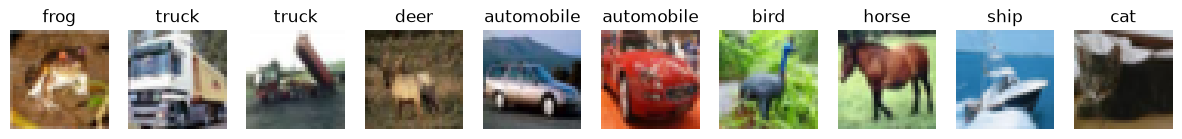

In [22]:
classes = cifar_train_subset.cifar_full.classes

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.247, 0.243, 0.261]).view(3, 1, 1)

plt.figure(figsize=(15, 3))

for i in range(10):
    image, label = cifar_train_subset[i]

    image = (image * std + mean).clamp(0, 1)

    plt.subplot(1, 10, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(classes[label])
    plt.axis("off")

plt.show()

In [23]:
supportpercent = 0.6

def create_support_query(dataset, supportpercent):
    support = []
    query = []

    for class_id in range(10):
        samples = [
            (image, label)
            for image, label in dataset
            if label == class_id
        ]

        indices = torch.randperm(len(samples)).tolist()
        samples = [samples[i] for i in indices]

        n_support = int(len(samples) * supportpercent)

        if not 0 < n_support < len(samples):
            raise ValueError("Невозможно разделить support и query")

        support.extend(samples[:n_support])
        query.extend(samples[n_support:])

    return support, query


train_support, train_query = create_support_query(
    cifar_train_subset, supportpercent
)

val_support, val_query = create_support_query(
    cifar_val_subset, supportpercent
)

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [26]:
def to_tensors(dataset):
    images = torch.stack([image for image, _ in dataset])
    labels = torch.tensor(
        [label for _, label in dataset],
        dtype=torch.long
    )

    return images.to(device), labels.to(device)


X_support, y_support = to_tensors(train_support)
X_query, y_query = to_tensors(train_query)

X_val_support, y_val_support = to_tensors(val_support)
X_val_query, y_val_query = to_tensors(val_query)

In [27]:
print("Train support:", X_support.shape)
print("Train query:", X_query.shape)

print("Val support:", X_val_support.shape)
print("Val query:", X_val_query.shape)

print("Support classes:", torch.bincount(y_support))
print("Query classes:", torch.bincount(y_query))

Train support: torch.Size([30, 3, 32, 32])
Train query: torch.Size([20, 3, 32, 32])
Val support: torch.Size([30, 3, 32, 32])
Val query: torch.Size([20, 3, 32, 32])
Support classes: tensor([3, 3, 3, 3, 3, 3, 3, 3, 3, 3], device='cuda:0')
Query classes: tensor([2, 2, 2, 2, 2, 2, 2, 2, 2, 2], device='cuda:0')


In [28]:
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128)
        )

    def forward(self, x):
        return self.network(x)


model = Encoder().to(device)
print(model)

Encoder(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=4096, out_features=128, bias=True)
  )
)


In [29]:
def get_prototypes(embeddings, labels):
    prototypes = []

    for class_id in range(10):
        class_embeddings = embeddings[labels == class_id]
        prototype = class_embeddings.mean(dim=0)
        prototypes.append(prototype)

    return torch.stack(prototypes)

In [30]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


def forward_episode(X_support, y_support, X_query, y_query):
    support_embeddings = model(X_support)
    query_embeddings = model(X_query)

    prototypes = get_prototypes(
        support_embeddings, y_support
    )

    distances = torch.cdist(
        query_embeddings, prototypes
    )

    logits = -distances

    loss = criterion(logits, y_query)

    predictions = logits.argmax(dim=1)
    accuracy = (predictions == y_query).float().mean()

    return loss, accuracy

In [31]:
EPOCHS = 2

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    # Training
    model.train()
    optimizer.zero_grad()

    loss, acc = forward_episode(
        X_support, y_support,
        X_query, y_query
    )

    loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_loss, val_acc = forward_episode(
            X_val_support, y_val_support,
            X_val_query, y_val_query
        )

    history["train_loss"].append(loss.item())
    history["train_acc"].append(acc.item())
    history["val_loss"].append(val_loss.item())
    history["val_acc"].append(val_acc.item())

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"loss: {loss.item():.4f} | "
        f"acc: {acc.item():.2%} | "
        f"val_loss: {val_loss.item():.4f} | "
        f"val_acc: {val_acc.item():.2%}"
    )

Epoch 1/2 | loss: 2.2601 | acc: 15.00% | val_loss: 2.0329 | val_acc: 30.00%
Epoch 2/2 | loss: 1.7825 | acc: 60.00% | val_loss: 1.8964 | val_acc: 25.00%


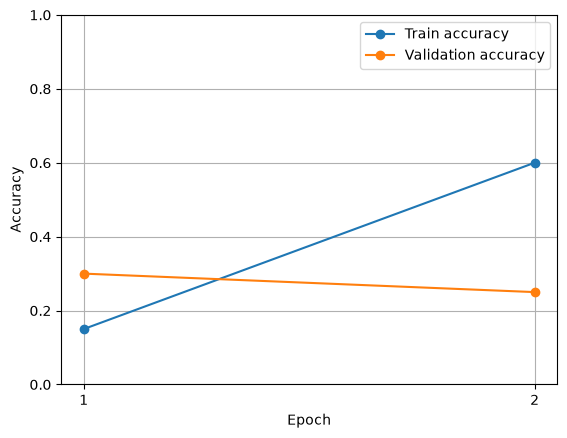

In [32]:
epochs = range(1, EPOCHS + 1)

plt.plot(epochs, history["train_acc"], "o-", label="Train accuracy")
plt.plot(epochs, history["val_acc"], "o-", label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.show()

In [33]:
N_QUERY = 10
MAX_SHOT = 10

train_pool = CifarSubset(
    root="./cifar",
    k_n=MAX_SHOT + N_QUERY,
    train=True,
    download=False,
    transform=transform
)

val_pool = CifarSubset(
    root="./cifar",
    k_n=MAX_SHOT + N_QUERY,
    train=False,
    download=False,
    transform=transform
)

In [34]:
def create_episode(dataset, n_shot):
    support = []
    query = []

    for class_id in range(10):
        samples = [
            (image, label)
            for image, label in dataset
            if label == class_id
        ]

        support.extend(samples[:n_shot])
        query.extend(samples[MAX_SHOT:MAX_SHOT + N_QUERY])

    X_s, y_s = to_tensors(support)
    X_q, y_q = to_tensors(query)

    return X_s, y_s, X_q, y_q

In [35]:
def run_experiment(n_shot, epochs=2):
    global model

    torch.manual_seed(42)

    model = Encoder().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    train_episode = create_episode(train_pool, n_shot)
    val_episode = create_episode(val_pool, n_shot)

    print(f"\n===== N_SHOT = {n_shot} =====")

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        loss, acc = forward_episode(*train_episode)

        loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            val_loss, val_acc = forward_episode(*val_episode)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"loss: {loss.item():.4f} | "
            f"acc: {acc.item():.2%} | "
            f"val_loss: {val_loss.item():.4f} | "
            f"val_acc: {val_acc.item():.2%}"
        )

    return val_acc.item()

In [36]:
results = {}

for n_shot in [1, 5, 10]:
    results[n_shot] = run_experiment(n_shot)


===== N_SHOT = 1 =====
Epoch 1/2 | loss: 2.2650 | acc: 16.00% | val_loss: 2.2362 | val_acc: 16.00%
Epoch 2/2 | loss: 1.9107 | acc: 38.00% | val_loss: 2.2335 | val_acc: 15.00%

===== N_SHOT = 5 =====
Epoch 1/2 | loss: 2.2677 | acc: 16.00% | val_loss: 2.1115 | val_acc: 21.00%
Epoch 2/2 | loss: 1.9840 | acc: 27.00% | val_loss: 2.1385 | val_acc: 19.00%

===== N_SHOT = 10 =====
Epoch 1/2 | loss: 2.2523 | acc: 19.00% | val_loss: 2.0923 | val_acc: 18.00%
Epoch 2/2 | loss: 1.9345 | acc: 37.00% | val_loss: 2.0808 | val_acc: 21.00%


In [37]:
import pandas as pd

df = pd.DataFrame({
    "N_SHOT": list(results.keys()),
    "Val Accuracy (%)": [
        round(acc * 100, 2)
        for acc in results.values()
    ]
})

display(df)

,N_SHOT,Val Accuracy (%)
0,1,15.0
1,5,19.0
2,10,21.0


Результаты показывают, что увеличение N_SHOT положительно влияет на итоговую точность модели.

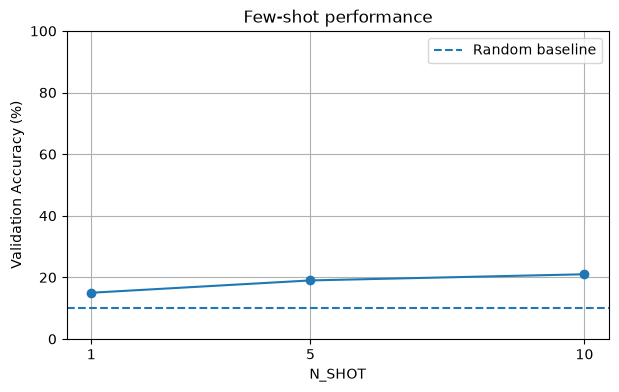

In [38]:
plt.figure(figsize=(7, 4))

plt.plot(
    list(results.keys()),
    [acc * 100 for acc in results.values()],
    marker="o"
)

plt.xlabel("N_SHOT")
plt.ylabel("Validation Accuracy (%)")
plt.title("Few-shot performance")
plt.xticks([1, 5, 10])
plt.axhline(10, linestyle="--", label="Random baseline")
plt.ylim(0, 100)
plt.legend()
plt.grid()
plt.show()

In [39]:
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomRotation(15)
])

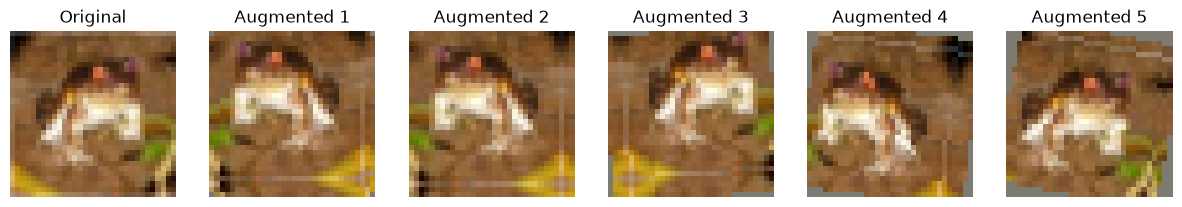

In [40]:
image, label = train_pool[0]

plt.figure(figsize=(15, 3))

for i in range(6):
    img = image if i == 0 else augmentation(image)

    img = (img * std + mean).clamp(0, 1)

    plt.subplot(1, 6, i + 1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title("Original" if i == 0 else f"Augmented {i}")
    plt.axis("off")

plt.show()

In [41]:
N_AUGMENTATIONS = 3

def augment_dataset(images, labels):
    augmented_images = [images]
    augmented_labels = [labels]

    for _ in range(N_AUGMENTATIONS):
        new_images = torch.stack([
            augmentation(image)
            for image in images
        ])

        augmented_images.append(new_images)
        augmented_labels.append(labels)

    return (
        torch.cat(augmented_images),
        torch.cat(augmented_labels)
    )

In [42]:
def run_augmented_experiment(n_shot, epochs=2):
    global model

    torch.manual_seed(42)

    model = Encoder().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    X_s, y_s, X_q, y_q = create_episode(
        train_pool, n_shot
    )

    val_episode = create_episode(val_pool, n_shot)

    print(f"\n===== AUGMENTED N_SHOT = {n_shot} =====")

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        X_s_aug, y_s_aug = augment_dataset(X_s, y_s)
        X_q_aug, y_q_aug = augment_dataset(X_q, y_q)

        loss, acc = forward_episode(
            X_s_aug, y_s_aug,
            X_q_aug, y_q_aug
        )

        loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            val_loss, val_acc = forward_episode(*val_episode)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"loss: {loss.item():.4f} | "
            f"acc: {acc.item():.2%} | "
            f"val_loss: {val_loss.item():.4f} | "
            f"val_acc: {val_acc.item():.2%}"
        )

    return val_acc.item()

In [43]:
augmented_results = {}

for n_shot in [1, 5, 10]:
    augmented_results[n_shot] = run_augmented_experiment(n_shot)


===== AUGMENTED N_SHOT = 1 =====
Epoch 1/2 | loss: 2.2659 | acc: 17.00% | val_loss: 2.2357 | val_acc: 16.00%
Epoch 2/2 | loss: 2.0670 | acc: 27.25% | val_loss: 2.2525 | val_acc: 14.00%

===== AUGMENTED N_SHOT = 5 =====
Epoch 1/2 | loss: 2.2766 | acc: 13.50% | val_loss: 2.1041 | val_acc: 25.00%
Epoch 2/2 | loss: 2.0932 | acc: 19.50% | val_loss: 2.1843 | val_acc: 22.00%

===== AUGMENTED N_SHOT = 10 =====
Epoch 1/2 | loss: 2.2583 | acc: 18.00% | val_loss: 2.0845 | val_acc: 18.00%
Epoch 2/2 | loss: 2.0099 | acc: 29.25% | val_loss: 2.0980 | val_acc: 22.00%


In [44]:
comparison = pd.DataFrame({
    "N_SHOT": [1, 5, 10],
    "Baseline (%)": [
        results[n] * 100 for n in [1, 5, 10]
    ],
    "Augmented (%)": [
        augmented_results[n] * 100 for n in [1, 5, 10]
    ]
})

comparison["Improvement (pp)"] = (
    comparison["Augmented (%)"] -
    comparison["Baseline (%)"]
)

display(comparison.round(2))

,N_SHOT,Baseline (%),Augmented (%),Improvement (pp)
0,1,15.0,14.0,-1.0
1,5,19.0,22.0,3.0
2,10,21.0,22.0,1.0


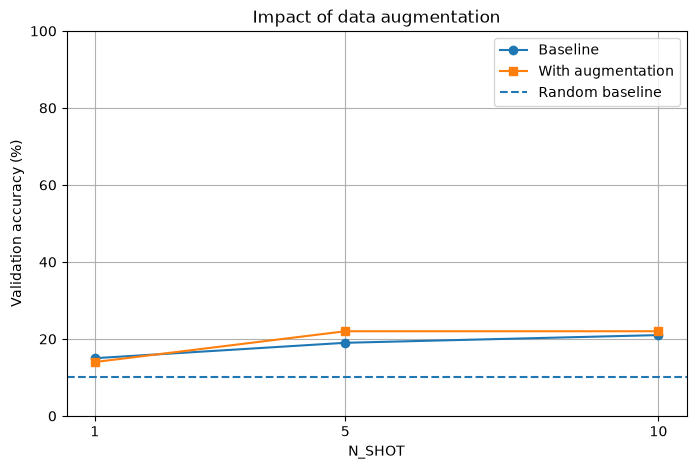

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    [1, 5, 10],
    [results[n] * 100 for n in [1, 5, 10]],
    "o-", label="Baseline"
)

plt.plot(
    [1, 5, 10],
    [augmented_results[n] * 100 for n in [1, 5, 10]],
    "s-", label="With augmentation"
)

plt.axhline(10, linestyle="--", label="Random baseline")

plt.xlabel("N_SHOT")
plt.ylabel("Validation accuracy (%)")
plt.title("Impact of data augmentation")
plt.xticks([1, 5, 10])
plt.ylim(0, 100)
plt.legend()
plt.grid()
plt.show()

In [46]:
class ImprovedEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128)
        )

    def forward(self, x):
        return self.network(x)

In [47]:
def run_improved_experiment(n_shot, epochs=2):
    global model

    torch.manual_seed(42)

    model = ImprovedEncoder().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    X_s, y_s, X_q, y_q = create_episode(
        train_pool, n_shot
    )

    val_episode = create_episode(val_pool, n_shot)

    print(f"\n===== IMPROVED N_SHOT = {n_shot} =====")

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        X_s_aug, y_s_aug = augment_dataset(X_s, y_s)
        X_q_aug, y_q_aug = augment_dataset(X_q, y_q)

        loss, acc = forward_episode(
            X_s_aug, y_s_aug,
            X_q_aug, y_q_aug
        )

        loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            val_loss, val_acc = forward_episode(*val_episode)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"loss: {loss.item():.4f} | "
            f"acc: {acc.item():.2%} | "
            f"val_loss: {val_loss.item():.4f} | "
            f"val_acc: {val_acc.item():.2%}"
        )

    return val_acc.item()

In [48]:
improved_results = {}

for n_shot in [1, 5, 10]:
    improved_results[n_shot] = run_improved_experiment(n_shot)


===== IMPROVED N_SHOT = 1 =====
Epoch 1/2 | loss: 2.1760 | acc: 18.00% | val_loss: 2.2417 | val_acc: 20.00%
Epoch 2/2 | loss: 1.8398 | acc: 34.00% | val_loss: 2.2448 | val_acc: 15.00%

===== IMPROVED N_SHOT = 5 =====
Epoch 1/2 | loss: 2.1749 | acc: 19.25% | val_loss: 2.2287 | val_acc: 24.00%
Epoch 2/2 | loss: 2.0480 | acc: 29.00% | val_loss: 2.2318 | val_acc: 21.00%

===== IMPROVED N_SHOT = 10 =====
Epoch 1/2 | loss: 2.1084 | acc: 25.00% | val_loss: 2.1951 | val_acc: 25.00%
Epoch 2/2 | loss: 1.8252 | acc: 33.75% | val_loss: 2.1872 | val_acc: 27.00%


In [49]:
final_comparison = pd.DataFrame({
    "N_SHOT": [1, 5, 10],
    "Baseline (%)": [
        results[n] * 100 for n in [1, 5, 10]
    ],
    "Augmented (%)": [
        augmented_results[n] * 100 for n in [1, 5, 10]
    ],
    "Improved (%)": [
        improved_results[n] * 100 for n in [1, 5, 10]
    ]
})

final_comparison["Total improvement (pp)"] = (
    final_comparison["Improved (%)"] -
    final_comparison["Baseline (%)"]
)

display(final_comparison.round(2))

,N_SHOT,Baseline (%),Augmented (%),Improved (%),Total improvement (pp)
0,1,15.0,14.0,15.0,0.0
1,5,19.0,22.0,21.0,2.0
2,10,21.0,22.0,27.0,6.0


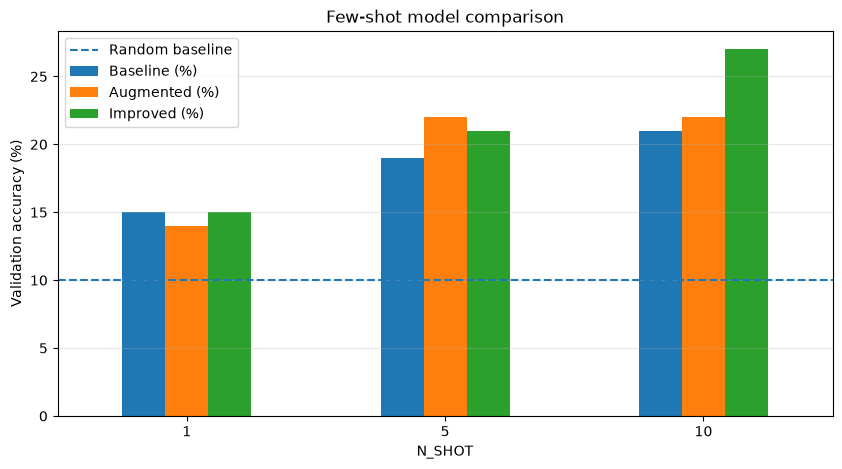

In [50]:
final_comparison.set_index("N_SHOT")[
    ["Baseline (%)", "Augmented (%)", "Improved (%)"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Few-shot model comparison")
plt.ylabel("Validation accuracy (%)")
plt.xlabel("N_SHOT")
plt.axhline(10, linestyle="--", label="Random baseline")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [51]:
class PrototypeNet(nn.Module):
    def __init__(self, input_dim=3, hid_dim=64, output_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            self.__conv_block(input_dim, hid_dim),
            self.__conv_block(hid_dim, hid_dim),
            self.__conv_block(hid_dim, hid_dim),
            self.__conv_block(hid_dim, output_dim),
        )

    def __conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        x = self.encoder(x)
        return x.view(x.size(0), -1)

In [52]:
def run_prototype_experiment(n_shot, epochs=2, steps=30):
    global model

    torch.manual_seed(42)

    model = PrototypeNet().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    X_s, y_s, X_q, y_q = create_episode(
        train_pool, n_shot
    )

    val_episode = create_episode(val_pool, n_shot)

    for epoch in range(epochs):
        model.train()

        losses = []
        accuracies = []

        for step in range(steps):
            optimizer.zero_grad()

            X_s_aug, y_s_aug = augment_dataset(X_s, y_s)
            X_q_aug, y_q_aug = augment_dataset(X_q, y_q)

            loss, acc = forward_episode(
                X_s_aug, y_s_aug,
                X_q_aug, y_q_aug
            )

            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            accuracies.append(acc.item())

        model.eval()

        with torch.no_grad():
            val_loss, val_acc = forward_episode(*val_episode)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"loss: {np.mean(losses):.4f} | "
            f"acc: {np.mean(accuracies):.2%} | "
            f"val_loss: {val_loss.item():.4f} | "
            f"val_acc: {val_acc.item():.2%}"
        )

    return val_acc.item()

In [55]:
prototype_results = {}

for n_shot in [1, 5, 10]:
    print(f"\n===== N_SHOT = {n_shot} =====")

    prototype_results[n_shot] = run_prototype_experiment(
        n_shot,
        epochs=2,
        steps=30
    )


===== N_SHOT = 1 =====
Epoch 1/2 | loss: 1.0775 | acc: 63.82% | val_loss: 2.6851 | val_acc: 23.00%
Epoch 2/2 | loss: 0.2177 | acc: 95.96% | val_loss: 2.7487 | val_acc: 27.00%

===== N_SHOT = 5 =====
Epoch 1/2 | loss: 1.0152 | acc: 66.52% | val_loss: 1.9893 | val_acc: 32.00%
Epoch 2/2 | loss: 0.1567 | acc: 97.61% | val_loss: 2.0046 | val_acc: 30.00%

===== N_SHOT = 10 =====
Epoch 1/2 | loss: 0.9497 | acc: 68.36% | val_loss: 1.9297 | val_acc: 36.00%
Epoch 2/2 | loss: 0.1451 | acc: 98.18% | val_loss: 1.8914 | val_acc: 36.00%


---

## 2. Few Shot Meta Learning
    
Мета обучение ставит перед собой задачу "научиться учиться". В нашем случае, "научиться классифицировать". Это более общая задача, ведь в случае обучения с учителем мы не просто "учимся классифицировать", а "учимся классифицировать на конкретные классы". Давайте подробнее рассмотрим один из Meta Learning алгоритмов.

__Model Agnostic Meta Learning (MAML)__ [ссылка на статью](https://arxiv.org/pdf/1703.03400.pdf)

Целью Few Shot мета обучения является обучение модели, которая может быстро адаптироваться к новой задаче, используя всего несколько объектов и итераций обучения. По сути, проблема __мета обучения__ рассматривает __целые задачи как обучающие примеры__. То есть целая задача классификации на кошек и собак — это один объект обучающей выборки, на машины и самолеты — второй объект обучающей выборки и так далее.

1. При решении эпизода __K__-way __N__-shot классификации мы каждый эпизод показываем __разные K классов__!
2. Во время эпизода мы используем _train_ выборку для того, чтобы обучать классификатор (любую привычную нам архитектуру, именно отсюда Model Agnostic в названии) так, как мы делали в обычной задаче классификации.
3. После эпизода мы используем ошибку и лосс на _val_ выборке (где у нас уже другое множество задач классификации) для того, чтобы провести мета обучение.
4. В конце обучения используется _test_ выборка, состоящая из нескольких _(не показанных ни в val, ни в test)_ задач классификации, на которой и измеряется качество работы модели.

![a](https://www.researchgate.net/publication/365372182/figure/fig2/AS:11431281097150362@1668482673888/The-problem-formulation-of-few-shot-metric-learning-as-an-episodic-training.png)

За счет этого и получается обобщение. Модель учится не просто отличать данные __K__ классов, а в целом - отличать между собой __любые K классов__ по __N__ примерам. А процесс мета обучения находит и адаптирует наиболее задаче-чувствительные параметры модели. Стоит отметить, что это всего лишь один представитель огромного множества Meta Learning алгоритмов.

P.S. Существует библиотека [pytorch-meta](https://github.com/tristandeleu/pytorch-meta) (это не официальная реализация от команды pytorch, но полезный функционал найти можно), в которой есть реализации известных Meta Learning алгоритмов, в том числе - [имплементация алгоритма MAML](https://github.com/tristandeleu/pytorch-meta/tree/master/examples/maml), который разобран выше.

---

Попробуйте реализовать алгоритм MAML на уже использованных нами ранее датасетах.

In [56]:
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import random

from torch import nn
from torch.func import functional_call
from torchvision import transforms

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

N_WAY = 2
N_SHOT = 5
N_QUERY = 10

INNER_LR = 0.01
META_LR = 0.001

INNER_STEPS = 3
META_BATCH_SIZE = 4
EPOCHS = 2
EPISODES_PER_EPOCH = 100

print(device)

cuda


In [57]:
maml_train_data = torchvision.datasets.CIFAR10(
    root="./cifar",
    train=True,
    download=False,
    transform=transform
)

maml_test_data = torchvision.datasets.CIFAR10(
    root="./cifar",
    train=False,
    download=False,
    transform=transform
)

print("Train:", len(maml_train_data))
print("Test:", len(maml_test_data))
print("Classes:", maml_train_data.classes)

Train: 50000
Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [58]:
def build_class_indices(dataset):
    targets = np.array(dataset.targets)

    return {
        c: np.where(targets == c)[0]
        for c in range(10)
    }


train_indices = build_class_indices(maml_train_data)
test_indices = build_class_indices(maml_test_data)

In [59]:
def sample_maml_episode(
    dataset,
    class_indices,
    available_classes,
    n_way=N_WAY,
    n_shot=N_SHOT,
    n_query=N_QUERY
):
    selected_classes = random.sample(
        available_classes, n_way
    )

    support_images = []
    support_labels = []

    query_images = []
    query_labels = []

    for local_label, class_id in enumerate(selected_classes):

        indices = np.random.choice(
            class_indices[class_id],
            size=n_shot + n_query,
            replace=False
        )

        for idx in indices[:n_shot]:
            image, _ = dataset[idx]

            support_images.append(image)
            support_labels.append(local_label)

        for idx in indices[n_shot:]:
            image, _ = dataset[idx]

            query_images.append(image)
            query_labels.append(local_label)

    return (
        torch.stack(support_images).to(device),
        torch.tensor(support_labels).long().to(device),
        torch.stack(query_images).to(device),
        torch.tensor(query_labels).long().to(device)
    )

In [61]:
META_TRAIN_CLASSES = [0, 1, 2, 3, 4, 5]
META_VAL_CLASSES = [6, 7]
META_TEST_CLASSES = [8, 9]

for name, class_ids in [
    ("Meta-train", META_TRAIN_CLASSES),
    ("Meta-validation", META_VAL_CLASSES),
    ("Meta-test", META_TEST_CLASSES)
]:
    print(
        name,
        [maml_train_data.classes[c] for c in class_ids]
    )

Meta-train ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog']
Meta-validation ['frog', 'horse']
Meta-test ['ship', 'truck']


In [62]:
Xs, ys, Xq, yq = sample_maml_episode(
    maml_train_data,
    train_indices,
    META_TRAIN_CLASSES
)

print("Support:", Xs.shape)
print("Support labels:", ys)

print("Query:", Xq.shape)
print("Query labels:", yq)

Support: torch.Size([10, 3, 32, 32])
Support labels: tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1], device='cuda:0')
Query: torch.Size([20, 3, 32, 32])
Query labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       device='cuda:0')


In [63]:
def build_class_indices(dataset):
    targets = np.array(dataset.targets)

    return {
        c: np.where(targets == c)[0]
        for c in range(10)
    }


train_indices = build_class_indices(maml_train_data)
test_indices = build_class_indices(maml_test_data)

In [64]:
def sample_maml_episode(
    dataset,
    class_indices,
    available_classes,
    n_way=N_WAY,
    n_shot=N_SHOT,
    n_query=N_QUERY
):
    selected_classes = random.sample(
        available_classes, n_way
    )

    support_images = []
    support_labels = []

    query_images = []
    query_labels = []

    for local_label, class_id in enumerate(selected_classes):

        indices = np.random.choice(
            class_indices[class_id],
            size=n_shot + n_query,
            replace=False
        )

        for idx in indices[:n_shot]:
            image, _ = dataset[idx]

            support_images.append(image)
            support_labels.append(local_label)

        for idx in indices[n_shot:]:
            image, _ = dataset[idx]

            query_images.append(image)
            query_labels.append(local_label)

    return (
        torch.stack(support_images).to(device),
        torch.tensor(support_labels).long().to(device),
        torch.stack(query_images).to(device),
        torch.tensor(query_labels).long().to(device)
    )

In [65]:
Xs, ys, Xq, yq = sample_maml_episode(
    maml_train_data,
    train_indices,
    META_TRAIN_CLASSES
)

print("Support:", Xs.shape)
print("Support labels:", ys)

print("Query:", Xq.shape)
print("Query labels:", yq)

Support: torch.Size([10, 3, 32, 32])
Support labels: tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1], device='cuda:0')
Query: torch.Size([20, 3, 32, 32])
Query labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       device='cuda:0')


In [66]:
class MAMLNet(nn.Module):
    def __init__(self, n_way=2):
        super().__init__()

        self.encoder = nn.Sequential(
            self.conv_block(3, 32),
            self.conv_block(32, 32),
            self.conv_block(32, 32),
            self.conv_block(32, 32)
        )

        self.classifier = nn.Linear(
            32 * 2 * 2, n_way
        )

    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = torch.flatten(x, 1)

        return self.classifier(x)


maml_model = MAMLNet(N_WAY).to(device)

meta_optimizer = torch.optim.Adam(
    maml_model.parameters(),
    lr=META_LR
)

print(maml_model)

MAMLNet(
  (encoder): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias

In [67]:
def inner_loop(model, Xs, ys, create_graph=True):

    params = dict(model.named_parameters())

    for _ in range(INNER_STEPS):

        logits = functional_call(
            model, params, (Xs,)
        )

        support_loss = F.cross_entropy(logits, ys)

        grads = torch.autograd.grad(
            support_loss,
            tuple(params.values()),
            create_graph=create_graph
        )

        params = {
            name: param - INNER_LR * grad
            for (name, param), grad
            in zip(params.items(), grads)
        }

    return params

In [68]:
def maml_episode(model, episode, create_graph=True):

    Xs, ys, Xq, yq = episode

    adapted_params = inner_loop(
        model,
        Xs,
        ys,
        create_graph=create_graph
    )

    query_logits = functional_call(
        model,
        adapted_params,
        (Xq,)
    )

    query_loss = F.cross_entropy(
        query_logits, yq
    )

    predictions = query_logits.argmax(dim=1)

    query_acc = (
        predictions == yq
    ).float().mean()

    return query_loss, query_acc

In [69]:
def evaluate_maml(
    model,
    available_classes,
    n_episodes=30,
    n_shot=N_SHOT
):
    model.eval()

    losses = []
    accuracies = []

    for _ in range(n_episodes):

        episode = sample_maml_episode(
            maml_test_data,
            test_indices,
            available_classes,
            n_shot=n_shot
        )

        loss, acc = maml_episode(
            model,
            episode,
            create_graph=False
        )

        losses.append(loss.item())
        accuracies.append(acc.item())

    return np.mean(losses), np.mean(accuracies)

In [70]:
maml_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    maml_model.train()

    epoch_losses = []
    epoch_accs = []

    for step in range(
        EPISODES_PER_EPOCH // META_BATCH_SIZE
    ):

        meta_optimizer.zero_grad()

        for _ in range(META_BATCH_SIZE):

            episode = sample_maml_episode(
                maml_train_data,
                train_indices,
                META_TRAIN_CLASSES
            )

            loss, acc = maml_episode(
                maml_model,
                episode,
                create_graph=True
            )

            (loss / META_BATCH_SIZE).backward()

            epoch_losses.append(loss.item())
            epoch_accs.append(acc.item())

        meta_optimizer.step()

    val_loss, val_acc = evaluate_maml(
        maml_model,
        META_VAL_CLASSES
    )

    train_loss = np.mean(epoch_losses)
    train_acc = np.mean(epoch_accs)

    maml_history["train_loss"].append(train_loss)
    maml_history["train_acc"].append(train_acc)
    maml_history["val_loss"].append(val_loss)
    maml_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train_loss: {train_loss:.4f} | "
        f"train_acc: {train_acc:.2%} | "
        f"val_loss: {val_loss:.4f} | "
        f"val_acc: {val_acc:.2%}"
    )

Epoch 1/2 | train_loss: 0.6858 | train_acc: 54.65% | val_loss: 0.6820 | val_acc: 57.83%
Epoch 2/2 | train_loss: 0.6524 | train_acc: 60.00% | val_loss: 0.6672 | val_acc: 59.17%


In [71]:
maml_results = {}

for n_shot in [1, 5, 10]:

    random.seed(123)
    np.random.seed(123)

    test_loss, test_acc = evaluate_maml(
        maml_model,
        META_TEST_CLASSES,
        n_episodes=100,
        n_shot=n_shot
    )

    maml_results[n_shot] = test_acc

    print(
        f"N_SHOT = {n_shot} | "
        f"test_loss: {test_loss:.4f} | "
        f"test_acc: {test_acc:.2%}"
    )

N_SHOT = 1 | test_loss: 0.7068 | test_acc: 55.35%
N_SHOT = 5 | test_loss: 0.6595 | test_acc: 61.75%
N_SHOT = 10 | test_loss: 0.6501 | test_acc: 62.70%
